# Laminar flames at Damköhler's (1940) conditions

Freely propagating, adiabatic, laminar premixed flames for the 22 propane–butane–oxygen mixtures of Damköhler (1940), sheet `Table 3` of `Damkohler_1940_tables.xlsx`, computed with Cantera and compared with his measured flame speeds and with the flame thickness used for his data in the paper (supplementary material, section S2.5). The fuel is Damköhler's technical propane, which from its mean molar mass of 46.1 g/mol he took to be 85 % propane and 15 % butane by volume (Damköhler 1940, section 3). It burns in pure oxygen at 18 °C (291.15 K) and 1 atm.

The mechanism, in `mechanisms/`, is set by `MECH_FILE`:

- `UCSD_mech.yaml`: UCSD mech, 57 species and 268 reactions;
- `USC_mech_II.yaml`: USC mech II (Wang *et al.* 2007), 111 species and 784 reactions.

The results of both are in `Damkohler_laminar_flames/`:

- `<mechanism>/flame_speed_technical_propane_<mechanism>_P_1.00.csv`: one row per mixture, with the laminar burning velocity, the peak temperature, the flame thickness by each definition, the Prandtl, Schmidt and Lewis numbers, densities and transport properties of the burned gas, and the activation temperature, Zel'dovich number and Markstein number (see the notes at the end);
- `<mechanism>/Array_tech_propane_<phi>_P_1.01.csv`: the structure of each flame: grid, temperature, velocity, density, heat release rate and mole fractions;
- `sL_Damkohler.pdf`: $s_L$ from each mechanism against Damköhler's flame speeds;
- `<mechanism>/dL_definitions.pdf`: the flame thickness by each definition.

Each figure is a single panel, as a PDF and a 1200 dpi PNG, in the style of `make_figures.ipynb`. The figures and tables at the end are drawn from the summary files, so they show both mechanisms whichever `MECH_FILE` is set. The notebook needs Cantera 3.1 or later (the results here are from 3.2.0), with NumPy, SciPy, pandas, Matplotlib and openpyxl. Run all cells, or `jupyter nbconvert --to notebook --execute --inplace Damkohler_laminar_flames.ipynb`, once for each `MECH_FILE`; this takes about 10 minutes with UCSD mech and 20 with USC mech II.

**Method.** The first flame, the mixture nearest stoichiometric, is solved from scratch in a 3 mm domain, which Cantera widens if needed. The other mixtures are then solved in order of $\phi$, outward from it, each from its neighbour's solution in steps of at most 0.15 in $\phi$. A second flame with the inlet 5 K warmer, solved from the converged one, gives the activation temperature.

In [1]:
import os, glob, time, math, warnings
import numpy as np
import pandas as pd
import cantera as ct
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import quad

print('Cantera', ct.__version__)
# some species have small jumps in cp, h or s at 1000 K in their source data; Cantera warns about them on loading
warnings.filterwarnings('ignore', message='NasaPoly2::validate')

MECH_FILE = 'UCSD_mech.yaml'          # or 'USC_mech_II.yaml'
MECH_DIR = 'mechanisms'
XLSX = 'Damkohler_1940_tables.xlsx'   # Damköhler's tables
ROOT = 'Damkohler_laminar_flames'     # results
LABELS = {'UCSD_mech': 'UCSD mech', 'USC_mech_II': 'USC mech II'}

MECH = os.path.join(MECH_DIR, MECH_FILE)
TAG = os.path.splitext(MECH_FILE)[0]
OUT = os.path.join(ROOT, TAG)
os.makedirs(OUT, exist_ok=True)

FUEL = 'C3H8:0.85, C4H10:0.15'        # technical propane, by volume
TU = 291.15                           # unburned temperature, K (18 C)
P = ct.one_atm                        # Pa
DT = 5.0                              # inlet-temperature step for the activation temperature, K
REFINE = dict(ratio=2, slope=0.03, curve=0.06, prune=0.01)   # grid criteria
DPHI_MAX = 0.15                       # largest step in phi between successive solves
CSV = dict(index=False, float_format='%.6g')                  # output files: six significant digits
print('mechanism:', MECH, '| output:', OUT)

Cantera 3.2.0
mechanism: mechanisms/UCSD_mech.yaml | output: Damkohler_laminar_flames/UCSD_mech


## Mechanisms

UCSD mech is the C$_0$–C$_4$ mechanism of the University of California at San Diego, from *Chemical-Kinetic Mechanisms for Combustion Applications* (Mechanical and Aerospace Engineering, Combustion Research, <https://web.eng.ucsd.edu/mae/groups/combustion/mechanism.html>). USC mech II is the H$_2$/CO/C$_1$–C$_4$ model of Wang *et al.* (2007), with the thermodynamic data of every species from its own [`thermdat.txt`](https://web.stanford.edu/group/haiwanglab/USC%20Mech%20II/Mechanisms/USC%20Mech%20II/thermdat.txt). A Cantera file of USC mech II whose NASA-9 data had been matched by formula from Burcat's database gave 48 species the data of another isomer, or corrupted polynomials: formaldehyde, for instance, carried the data of hydroxymethylene, 234 kJ/mol higher in heat of formation. With those data, reverse rate constants reached $10^{33}$ cm$^3$/(mol s) at flame temperatures and none of these flames converged. The header of `USC_mech_II.yaml` lists the corrections. As a check, the cell below compares the enthalpy of combustion of formaldehyde in both mechanisms with GRI-Mech 3.0, which comes with Cantera.

In [2]:
def ch2o_combustion(g):
    # enthalpy of CH2O + O2 -> CO2 + H2O at 298 K, kJ/mol
    h = lambda s: g.species(s).thermo.h(298.15) / 1e6
    return h('CO2') + h('H2O') - h('CH2O') - h('O2')


for path in sorted(glob.glob(os.path.join(MECH_DIR, '*.yaml'))) + ['gri30.yaml']:
    g = ct.Solution(path)
    print(f'{os.path.basename(path):16s} {g.n_species:4d} species {g.n_reactions:4d} reactions | '
          f'CH2O + O2 -> CO2 + H2O at 298 K: {ch2o_combustion(g):.1f} kJ/mol')

gas = ct.Solution(MECH)

UCSD_mech.yaml     57 species  268 reactions | CH2O + O2 -> CO2 + H2O at 298 K: -526.8 kJ/mol
USC_mech_II.yaml  111 species  784 reactions | CH2O + O2 -> CO2 + H2O at 298 K: -526.8 kJ/mol
gri30.yaml         53 species  325 reactions | CH2O + O2 -> CO2 + H2O at 298 K: -526.8 kJ/mol


## Damköhler's mixtures and measured flame speeds

`Table 3` of the workbook lists each test: tube diameter, propane content, equivalence ratio $\phi$ with oxygen, kinematic viscosity $\nu$, mean velocity, the flame speeds $w_{f,\min}$ and $w_{f,\max}$ computed from the outer and inner boundaries of the luminous zone, and the tube Reynolds number $\mathit{Re}_d$. Tests with $\mathit{Re}_d < 2300$ are laminar; Damköhler found that $w_{f,\min}$ also agreed with the laminar flame speed in the turbulent tests, except tests 45 and 52.

In [3]:
t3 = pd.read_excel(XLSX, sheet_name='Table 3').dropna(subset=['Test'])
t3 = t3.rename(columns={'Tube diameter (mm)': 'd (mm)', '% C3H8 (%)': 'fuel (%)', 'u (cm/s)': 'U (cm/s)'})
t3['Test'] = t3['Test'].astype(int)
t3['Phi_O2'] = t3['Phi_O2'].astype(float)
t3['laminar'] = t3['Re_d'] < 2300
phis = np.sort(t3['Phi_O2'].unique())
print(len(phis), 'mixtures, phi =', np.round(phis, 4))
t3[['Test', 'd (mm)', 'fuel (%)', 'Phi_O2', 'Re_d', 'laminar', 'nu (cm2/s)', 'wf_min (cm/s)', 'wf_max (cm/s)']]

22 mixtures, phi = [0.2336 0.5142 0.6937 0.7294 0.7417 0.8092 0.8148 0.8825 0.8983 1.0513
 1.2464 1.2713 1.3747 1.3973 1.7324 1.8368 1.8377 1.9276 1.9394 1.9889
 2.1821 2.2553]


,Test,d (mm),fuel (%),Phi_O2,Re_d,laminar,nu (cm2/s),wf_min (cm/s),wf_max (cm/s)
0,11,1.385,8.96,0.514236,1555.0,True,0.140,202.0,NaN
1,12,1.385,12.43,0.741655,1421.0,True,0.135,266.0,NaN
2,22,1.385,12.25,0.729416,3960.0,False,0.135,248.5,NaN
3,25,1.385,11.72,0.693668,2933.0,False,0.136,252.7,NaN
4,49,1.385,16.75,1.051276,1119.0,True,0.129,275.0,321.0
5,50,1.385,26.02,1.837720,1098.0,True,0.117,145.2,205.0
6,51,1.385,21.10,1.397307,2800.0,False,0.123,211.4,291.9
7,52,1.385,27.07,1.939404,3035.0,False,0.116,50.2,NaN
8,53,1.385,14.45,0.882539,3675.0,False,0.132,262.0,434.7
9,28,2.180,4.28,0.233629,612.0,True,0.147,72.2,NaN


## Solver

`mixture` sets the unburned state. `start_flame` solves the first flame from scratch in a 3 mm domain, first on a coarse grid and then with the final grid criteria. `march` moves a converged flame to a new $\phi$ in steps of at most `DPHI_MAX`, halving a step that fails.

In [4]:
def mixture(phi, T=TU):
    # unburned technical propane with pure O2
    gas.TP = T, P
    gas.set_equivalence_ratio(phi, FUEL, 'O2:1.0')
    return gas.X.copy()


def message(err):
    lines = [l.strip() for l in str(err).splitlines() if l.strip() and not l.startswith('*')]
    return lines[-1] if lines else str(err)


def solve_at(f, phi, T=TU):
    f.inlet.T = T
    f.inlet.X = mixture(phi, T)
    f.solve(loglevel=0, refine_grid=True, auto=False)


def march(f, phi_from, phi_to, T=TU, dphi=DPHI_MAX, depth=0):
    # move a converged flame from phi_from to phi_to in steps of at most dphi, halving any step that fails
    n = max(1, math.ceil(abs(phi_to - phi_from) / dphi - 1e-9))
    steps = np.linspace(phi_from, phi_to, n + 1)
    for a, b in zip(steps[:-1], steps[1:]):
        saved = f.to_array()
        try:
            solve_at(f, b, T)
        except ct.CanteraError:
            if depth >= 3:
                raise
            f.from_array(saved)                       # back to the last converged flame
            march(f, a, b, T, abs(b - a) / 2, depth + 1)


def start_flame(phi, width=0.003):
    t0 = time.time()
    mixture(phi)
    f = ct.FreeFlame(gas, width=width)
    f.transport_model = 'mixture-averaged'
    f.set_refine_criteria(ratio=3, slope=0.06, curve=0.12)
    f.solve(loglevel=0, auto=True)
    print(f'  coarse grid: s_L = {f.velocity[0]:6.3f} m/s, T_b = {f.T[-1]:5.0f} K, {len(f.grid)} points, '
          f'domain {f.grid[-1] * 1e3:.1f} mm ({time.time() - t0:.0f} s)')
    f.set_refine_criteria(**REFINE)
    f.solve(loglevel=0, refine_grid=True, auto=False)
    print(f'  final grid: s_L = {f.velocity[0]:6.3f} m/s, T_b = {f.T[-1]:5.0f} K, {len(f.grid)} points ({time.time() - t0:.0f} s)')
    return f

## Flame properties

Transport properties of the burned gas are taken at the end of the domain. $D^* = \lambda_b/(\rho_u c_{p,b})$ is the diffusivity of Peters (2000), $D_{\mathrm{th}} = \lambda / (\rho c_p)$ the thermal diffusivity (`alpha` in the column names) and $D$ the mixture-averaged diffusivity of the deficient reactant. $\nu_u/s_L$ and $D_{\mathrm{th},u}/s_L$ use the unburned state. The activation temperature follows from $s_L \propto \exp(-T_a/2T_b)$ between the flame and one with the inlet `DT` warmer, and the Markstein number from Clavin's (1985) expression with the thickness $(T_\mathrm{inner} - T_u)/\max(\mathrm{d}T/\mathrm{d}x)$, where $T_\mathrm{inner}$ is the temperature at the steepest gradient.

In [5]:
def state_at(f, i):
    gas.TPY = f.T[i], P, f.Y[:, i]
    return gas


def properties(f, phi):
    z, T = f.grid, f.T
    grad = np.gradient(T, z)
    i_max = int(np.argmax(grad))
    sL, Tb, Tu = f.velocity[0], T.max(), T.min()
    T_inner = float(T[i_max])
    deficient = 'C3H8' if phi <= 1.0 else 'O2'
    g = state_at(f, 0)                                  # unburned state
    rho_u, nu_u = g.density, g.viscosity / g.density
    alpha_u = g.thermal_conductivity / (g.density * g.cp_mass)
    g = state_at(f, len(z) - 1)                         # burned state
    lam_b, cp_b, cv_b, rho_b = g.thermal_conductivity, g.cp_mass, g.cv_mass, g.density
    D_star = lam_b / cp_b / rho_u
    nu_b = g.viscosity / rho_b
    alpha_b = lam_b / (rho_b * cp_b)
    D_b = g.mix_diff_coeffs[g.species_index(deficient)]
    return {'phi[-]': phi, 'Sl[m/s]': sL, 'Tmax[K]': Tb,
            'deltaL[mm](gradT)': (Tb - Tu) / grad.max() * 1e3,
            'deltaL[mm](D*)': D_star / sL * 1e3, 'deltaL[mm](nu)': nu_b / sL * 1e3, 'deltaL[mm](alpha)': alpha_b / sL * 1e3,
            'Pr[-]': nu_b / alpha_b, 'Sc[-]': nu_b / D_b, 'Le[-]': alpha_b / D_b,
            'D*[mm2/s]': D_star * 1e6, 'nu[mm2/s]': nu_b * 1e6, 'alpha[mm2/s]': alpha_b * 1e6, 'D[mm2/s]': D_b * 1e6,
            'rho_u[kg/m3]': rho_u, 'rho_b[kg/m3]': rho_b, 'cp[kJ/kgK]': cp_b / 1e3, 'cv[kJ/kgK]': cv_b / 1e3,
            'lambda[W/mK]': lam_b, 'HRR[W/m3]': f.heat_release_rate.max(), 'Tinner[K]': T_inner,
            'deltaL[mm](inner)': (T_inner - Tu) / grad.max() * 1e3,
            'deltaL[mm](nu_u)': nu_u / sL * 1e3, 'deltaL[mm](alpha_u)': alpha_u / sL * 1e3}


def zfk(props, sL2, Tb2):
    sL1, Tb1, Tu = props['Sl[m/s]'], props['Tmax[K]'], TU
    T_act = -2.0 * (np.log(sL2) - np.log(sL1)) / (1.0 / Tb2 - 1.0 / Tb1)
    beta = T_act * (Tb1 - Tu) / Tb1**2
    Theta = Tb1 / Tu
    integral = quad(lambda x: 1.0 if x == 1.0 else np.log(x) / (x - 1.0), 1.0, Theta)[0]
    Ma = Theta / (Theta - 1.0) * np.log(Theta) + beta * (props['Le[-]'] - 1.0) / 2.0 * integral
    return {'T_act[K]': T_act, 'beta[-]': beta, 'Markstein_num[-]': Ma,
            'Markstein_len[mm]': Ma * props['deltaL[mm](inner)'], 'Sl_pert[m/s]': sL2, 'Tmax_pert[K]': Tb2}


def save_profile(f, phi):
    df = pd.DataFrame({'grid[m]': f.grid, 'T[K]': f.T, 'velocity[m/s]': f.velocity,
                       'density[kg/m3]': f.density, 'HRR[W/m3]': f.heat_release_rate})
    X = pd.DataFrame(f.X.T, columns=['X_' + s for s in gas.species_names])
    pd.concat([df, X], axis=1).to_csv(os.path.join(OUT, f'Array_tech_propane_{phi:.4f}_P_{P / 1e5:.2f}.csv'), **CSV)

## Flames

The first flame is the mixture nearest stoichiometric; the rich branch is then solved upward and the lean branch downward from it.

In [6]:
t_start = time.time()
i0 = int(np.argmin(np.abs(np.log(phis))))
print(f'start-up at phi = {phis[i0]:.4f}')
f = start_flame(phis[i0])
start = f.to_array()

rows, failed = {}, []
for branch in (list(range(i0, len(phis))), list(range(i0, -1, -1))):
    f.from_array(start)
    phi_prev = phis[i0]
    for i in branch:
        phi = phis[i]
        if phi in rows:
            continue
        t0 = time.time()
        try:
            march(f, phi_prev, phi)
            props = properties(f, phi)
            save_profile(f, phi)
            solve_at(f, phi, TU + DT)                          # warmer inlet, from the converged flame
            props.update(zfk(props, f.velocity[0], f.T.max()))
            rows[phi] = props
            print(f"Solved phi = {phi:.4f} | sL = {props['Sl[m/s]']:.3f} m/s | Tb = {props['Tmax[K]']:.1f} K"
                  f" | {len(f.grid)} points | {time.time() - t0:.0f} s")
            phi_prev = phi
        except ct.CanteraError as err:
            failed.append(phi)
            print(f'FAILED phi = {phi:.4f}: {message(err)[:150]}')
            f.from_array(start)
            phi_prev = phis[i0]
print(f'{len(rows)} of {len(phis)} mixtures solved in {(time.time() - t_start) / 60:.1f} min; failed: {failed}')

res = pd.DataFrame([rows[p] for p in sorted(rows)])
res.to_csv(os.path.join(OUT, f'flame_speed_technical_propane_{TAG}_P_1.00.csv'), **CSV)
print('T_act ranges from %.1e to %.1e K: see the notes at the end before using T_act, beta or the Markstein number.'
      % (res['T_act[K]'].min(), res['T_act[K]'].max()))
res.round(4)

start-up at phi = 1.0513


  coarse grid: s_L =  2.909 m/s, T_b =  3099 K, 272 points, domain 6.0 mm (19 s)


  final grid: s_L =  2.908 m/s, T_b =  3098 K, 526 points (29 s)


Solved phi = 1.0513 | sL = 2.908 m/s | Tb = 3110.2 K | 526 points | 5 s


Solved phi = 1.2464 | sL = 2.650 m/s | Tb = 3128.2 K | 553 points | 20 s


...

Solved phi = 0.7294 | sL = 2.955 m/s | Tb = 3029.6 K | 538 points | 7 s


Solved phi = 0.6937 | sL = 2.920 m/s | Tb = 3014.9 K | 539 points | 7 s


Solved phi = 0.5142 | sL = 2.548 m/s | Tb = 2906.5 K | 563 points | 25 s


Solved phi = 0.2336 | sL = 0.959 m/s | Tb = 2363.5 K | 681 points | 68 s
22 of 22 mixtures solved in 11.2 min; failed: []
T_act ranges from 1.2e+05 to 8.0e+05 K: see the notes at the end before using T_act, beta or the Markstein number.


,phi[-],Sl[m/s],Tmax[K],deltaL[mm](gradT),deltaL[mm](D*),deltaL[mm](nu),deltaL[mm](alpha),Pr[-],Sc[-],Le[-],...,Tinner[K],deltaL[mm](inner),deltaL[mm](nu_u),deltaL[mm](alpha_u),T_act[K],beta[-],Markstein_num[-],Markstein_len[mm],Sl_pert[m/s],Tmax_pert[K]
0,0.2336,0.9588,2363.5270,0.1638,0.0911,0.5382,0.7818,0.6884,1.2449,1.8084,...,1196.6217,0.0716,0.0146,0.0197,123044.3902,45.6467,65.7622,4.7070,0.9815,2365.6525
1,0.5142,2.5484,2906.5200,0.0827,0.0406,0.3195,0.4913,0.6504,1.2985,1.9963,...,1309.4241,0.0322,0.0051,0.0068,583194.1136,180.5509,357.5000,11.5167,2.5976,2907.0735
2,0.6937,2.9196,3014.8661,0.0748,0.0371,0.3168,0.5078,0.6240,1.3287,2.1294,...,1346.3470,0.0290,0.0042,0.0057,676110.8655,202.6020,464.8619,13.4732,2.9757,3015.3784
3,0.7294,2.9555,3029.5573,0.0741,0.0369,0.3193,0.5159,0.6189,1.3338,2.1552,...,1351.4916,0.0287,0.0041,0.0056,684125.5085,204.1153,480.4221,13.7882,3.0122,3030.0676
4,0.7417,2.9654,3034.2209,0.0739,0.0369,0.3203,0.5190,0.6172,1.3355,2.1639,...,1353.0031,0.0286,0.0041,0.0055,705793.0026,210.2907,499.1009,14.2829,3.0221,3034.7150
5,0.8092,3.0012,3057.2290,0.0733,0.0369,0.3273,0.5385,0.6078,1.3444,2.2119,...,1370.2006,0.0286,0.0040,0.0054,729638.1439,215.9316,535.9823,15.3168,3.0584,3057.7129
6,0.8148,3.0027,3058.9199,0.0732,0.0369,0.3280,0.5403,0.6071,1.3451,2.2157,...,1370.5850,0.0286,0.0040,0.0054,731115.2806,216.2617,538.6971,15.3836,3.0599,3059.4033
7,0.8825,3.0055,3077.5456,0.0731,0.0373,0.3373,0.5641,0.5980,1.3528,2.2622,...,1373.4909,0.0284,0.0039,0.0053,741568.2088,218.1649,566.2455,16.0826,3.0625,3078.0260
8,0.8983,3.0024,3081.3906,0.0732,0.0374,0.3398,0.5702,0.5959,1.3545,2.2728,...,1373.7304,0.0284,0.0039,0.0053,797793.7277,234.4438,613.8929,17.4274,3.0593,3081.8371
9,1.0513,2.9083,3110.2479,0.0749,0.0393,0.3692,0.6401,0.5767,0.8289,1.4374,...,1390.5126,0.0292,0.0039,0.0052,711648.5549,207.3890,189.5288,5.5327,2.9633,3110.7573


## Figures

Plot style of `make_figures.ipynb`, with the symbol of Damköhler (1940) in the paper.

In [7]:
plt.style.use('classic')
matplotlib.rcParams['savefig.bbox'] = 'tight'
INK = 'k'
MS, MEW = 10, 1.8                      # marker size and edge width
LABEL, TICK, LEGEND, NOTE = 22, 14, 14, 16
PANEL = (7, 5)                         # inches, one panel per file
TEXT_BG = dict(facecolor='white', edgecolor='none', alpha=0.8, boxstyle='square,pad=0.05')  # tight background behind text on plots
GRID = dict(which='both', color='k', linestyle='-', linewidth=0.5, alpha=0.15)
DAMK = 'p'                             # symbol of Damköhler (1940) in the paper
TITLE = 'Propane–butane–oxygen\n' r'fuel 85% C$_3$H$_8$, 15% C$_4$H$_{10}$ (by vol.)'


def panel():
    fig, ax = plt.subplots(figsize=PANEL)
    ax.tick_params(axis='both', which='major', labelsize=TICK)
    ax.set_title(TITLE, fontsize=LEGEND)
    return fig, ax


def save(fig, folder, name):
    for ext, kw in (('.pdf', {}), ('.png', {'dpi': 1200})):
        path = os.path.join(folder, name + ext)
        if os.path.exists(path):
            os.remove(path)  # on Windows an open viewer can block overwriting in place
        fig.savefig(path, **kw)
    plt.show()


def damk(ax, x, y, c=INK, **kw):
    ax.plot(x, y, ls='none', marker=DAMK, mfc='none', mec=c, mew=MEW, ms=MS, **kw)

### Laminar burning velocity

$s_L$ from each mechanism with results in `Damkohler_laminar_flames/`, against Damköhler's flame speeds: $w_{f,\min}$ (black) and $w_{f,\max}$ (blue) of the laminar tests, and $w_{f,\min}$ of the turbulent tests (grey).

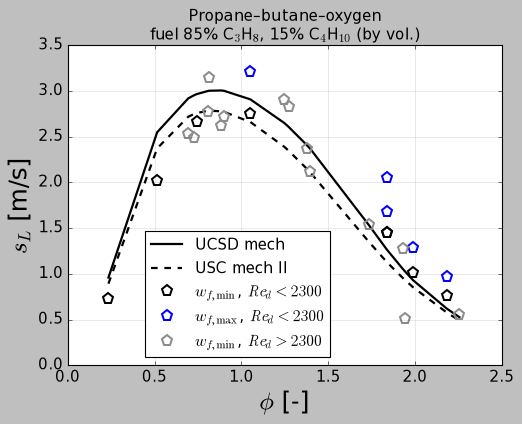

In [8]:
lam, turb = t3[t3['laminar']], t3[~t3['laminar']]
LINES = {'UCSD_mech': '-', 'USC_mech_II': '--'}
fig, ax = panel()
for path in sorted(glob.glob(os.path.join(ROOT, '*', 'flame_speed_technical_propane_*_P_1.00.csv'))):
    name = os.path.basename(os.path.dirname(path))
    other = pd.read_csv(path)
    ax.plot(other['phi[-]'], other['Sl[m/s]'], color=INK, ls=LINES.get(name, ':'), lw=2, label=LABELS.get(name, name))
damk(ax, lam['Phi_O2'], lam['wf_min (cm/s)'] / 100, label=r'$w_{f,\min}$, $\mathit{Re}_d < 2300$')
damk(ax, lam['Phi_O2'], lam['wf_max (cm/s)'] / 100, c='b', label=r'$w_{f,\max}$, $\mathit{Re}_d < 2300$')
damk(ax, turb['Phi_O2'], turb['wf_min (cm/s)'] / 100, c='0.55', label=r'$w_{f,\min}$, $\mathit{Re}_d > 2300$')
ax.set_xlim(0, 2.5); ax.set_ylim(0, 3.5)
ax.set_xlabel(r'$\phi$ [-]', fontsize=LABEL)
ax.set_ylabel(r'$s_L$ [m/s]', fontsize=LABEL)
ax.legend(loc='lower left', bbox_to_anchor=(0.16, 0.0), fontsize=LEGEND, numpoints=1)
ax.grid(**GRID)
save(fig, ROOT, 'sL_Damkohler')

### Flame thickness

The flame thickness by each definition, one figure per mechanism, with $\nu / w_{f,\min}$ from Damköhler's own viscosities, the 0.1 mm thickness he gives for the luminous zone of his laminar flames, and the $\delta_L = 0.01$ mm, a tenth of it, used for his flames in the paper (supplementary material, section S2.5). Each figure is saved as `dL_definitions` in the folder of its mechanism.

In [9]:
DEFINITIONS = [('deltaL[mm](gradT)', INK, '-', r'$(T_b - T_u)/\max(\mathrm{d}T/\mathrm{d}x)$'),
               ('deltaL[mm](D*)', INK, ':', r'$D{}^{*}/s_L$'),
               ('deltaL[mm](alpha)', 'r', '-', r'$D_{\mathrm{th},b}/s_L$'),
               ('deltaL[mm](nu)', 'r', '--', r'$\nu_b/s_L$'),
               ('deltaL[mm](alpha_u)', 'b', '-', r'$D_{\mathrm{th},u}/s_L$'),
               ('deltaL[mm](nu_u)', 'b', '--', r'$\nu_u/s_L$')]


def results(tag):
    # summary file of a mechanism, or None if the notebook has not been run with it
    path = os.path.join(ROOT, tag, f'flame_speed_technical_propane_{tag}_P_1.00.csv')
    if not os.path.exists(path):
        print(f'No results for {LABELS.get(tag, tag)}: run the notebook with MECH_FILE = {tag + ".yaml"!r}')
        return None
    return pd.read_csv(path)


def thickness_figure(tag):
    summary = results(tag)
    if summary is None:
        return
    fig, ax = panel()
    for col, c, ls, lab in DEFINITIONS:
        ax.semilogy(summary['phi[-]'], summary[col], color=c, ls=ls, lw=2, label=lab)
    damk(ax, t3['Phi_O2'], t3['nu (cm2/s)'] / t3['wf_min (cm/s)'] * 10, label=r'$\nu/w_{f,\min}$, Damköhler (1940)')
    for y, text in [(0.1, 'luminous zone'), (0.01, r'$\delta_L$ = luminous zone$/10$')]:
        ax.axhline(y, color='0.6', lw=5, alpha=0.6, zorder=0)
        ax.text(1.0, y * 1.15, text, fontsize=NOTE, ha='center', va='bottom', bbox=TEXT_BG)
    ax.text(0.03, 0.96, LABELS.get(tag, tag), transform=ax.transAxes, fontsize=NOTE, ha='left', va='top', bbox=TEXT_BG)
    ax.set_xlim(0, 2.5); ax.set_ylim(2e-3, 6)
    ax.set_xlabel(r'$\phi$ [-]', fontsize=LABEL)
    ax.set_ylabel(r'$\delta_L$ [mm]', fontsize=LABEL)
    ax.legend(loc='upper left', bbox_to_anchor=(0.99, 1.02), fontsize=LEGEND, numpoints=1)
    ax.grid(**GRID)
    save(fig, os.path.join(ROOT, tag), 'dL_definitions')

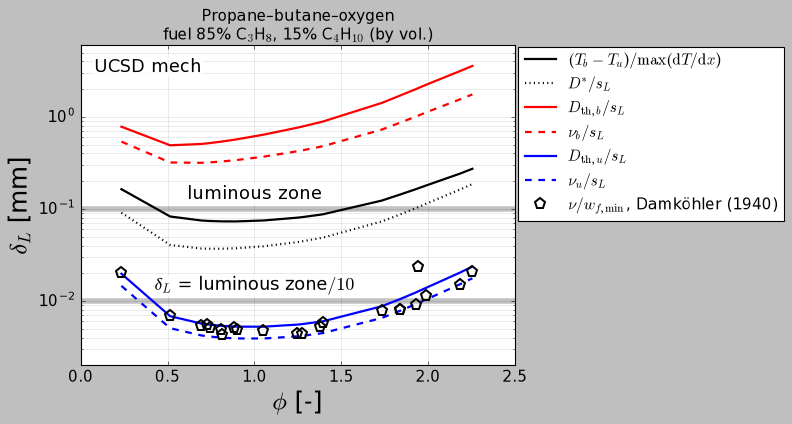

In [10]:
thickness_figure('UCSD_mech')

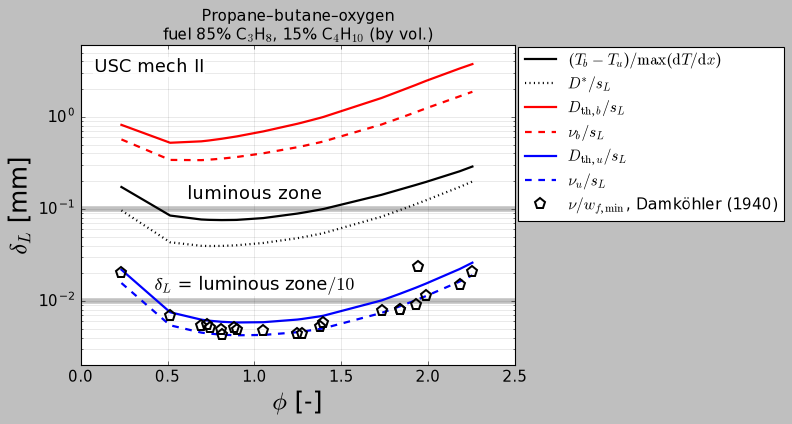

In [11]:
thickness_figure('USC_mech_II')

## Comparison with Damköhler's tests

For each test of `Table 3`, the computed $s_L$ and flame thicknesses at its $\phi$, and the ratios of Damköhler's flame speeds to $s_L$, one table per mechanism. The medians are over the laminar tests ($\mathit{Re}_d < 2300$).

In [12]:
def comparison_table(tag):
    summary = results(tag)
    if summary is None:
        return None
    cmp = t3[['Test', 'Phi_O2', 'laminar', 'nu (cm2/s)', 'wf_min (cm/s)', 'wf_max (cm/s)']].copy()
    cmp['sL (cm/s)'] = np.interp(cmp['Phi_O2'], summary['phi[-]'], summary['Sl[m/s]']) * 100
    cmp['wf_min/sL'] = cmp['wf_min (cm/s)'] / cmp['sL (cm/s)']
    cmp['wf_max/sL'] = cmp['wf_max (cm/s)'] / cmp['sL (cm/s)']
    for col in ('deltaL[mm](gradT)', 'deltaL[mm](nu_u)', 'deltaL[mm](alpha_u)', 'deltaL[mm](nu)'):
        cmp[col] = np.interp(cmp['Phi_O2'], summary['phi[-]'], summary[col])
    laminar = cmp['laminar']
    print(f"{LABELS.get(tag, tag)}, laminar tests: median wf_min/sL = {cmp.loc[laminar, 'wf_min/sL'].median():.2f}, "
          f"median wf_max/sL = {cmp.loc[laminar, 'wf_max/sL'].median():.2f}")
    return cmp.round(4)

In [13]:
comparison_table('UCSD_mech')

UCSD mech, laminar tests: median wf_min/sL = 1.01, median wf_max/sL = 1.38


,Test,Phi_O2,laminar,nu (cm2/s),wf_min (cm/s),wf_max (cm/s),sL (cm/s),wf_min/sL,wf_max/sL,deltaL[mm](gradT),deltaL[mm](nu_u),deltaL[mm](alpha_u),deltaL[mm](nu)
0,11,0.5142,True,0.140,202.0,NaN,254.8427,0.7926,NaN,0.0827,0.0051,0.0068,0.3195
1,12,0.7417,True,0.135,266.0,NaN,296.5430,0.8970,NaN,0.0739,0.0041,0.0055,0.3203
2,22,0.7294,False,0.135,248.5,NaN,295.5450,0.8408,NaN,0.0741,0.0041,0.0056,0.3193
3,25,0.6937,False,0.136,252.7,NaN,291.9580,0.8655,NaN,0.0748,0.0042,0.0057,0.3168
4,49,1.0513,True,0.129,275.0,321.0,290.8312,0.9456,1.1037,0.0749,0.0039,0.0052,0.3692
5,50,1.8377,True,0.117,145.2,205.0,126.4661,1.1481,1.6210,0.1430,0.0078,0.0104,0.8632
6,51,1.3973,False,0.123,211.4,291.9,236.4807,0.8939,1.2344,0.0876,0.0045,0.0060,0.4818
7,52,1.9394,False,0.116,50.2,NaN,103.2011,0.4864,NaN,0.1664,0.0094,0.0126,1.0253
8,53,0.8825,False,0.132,262.0,434.7,300.5480,0.8717,1.4464,0.0731,0.0039,0.0053,0.3373
9,28,0.2336,True,0.147,72.2,NaN,95.8850,0.7530,NaN,0.1638,0.0146,0.0197,0.5382


In [14]:
comparison_table('USC_mech_II')

USC mech II, laminar tests: median wf_min/sL = 1.11, median wf_max/sL = 1.50


,Test,Phi_O2,laminar,nu (cm2/s),wf_min (cm/s),wf_max (cm/s),sL (cm/s),wf_min/sL,wf_max/sL,deltaL[mm](gradT),deltaL[mm](nu_u),deltaL[mm](alpha_u),deltaL[mm](nu)
0,11,0.5142,True,0.140,202.0,NaN,237.2057,0.8516,NaN,0.0847,0.0054,0.0075,0.3406
1,12,0.7417,True,0.135,266.0,NaN,275.8170,0.9644,NaN,0.0760,0.0044,0.0061,0.3431
2,22,0.7294,False,0.135,248.5,NaN,274.9990,0.9036,NaN,0.0761,0.0044,0.0061,0.3418
3,25,0.6937,False,0.136,252.7,NaN,271.8970,0.9294,NaN,0.0767,0.0045,0.0063,0.3387
4,49,1.0513,True,0.129,275.0,321.0,266.0663,1.0336,1.2065,0.0795,0.0043,0.0059,0.4023
5,50,1.8377,True,0.117,145.2,205.0,112.7751,1.2875,1.8178,0.1624,0.0087,0.0120,0.9730
6,51,1.3973,False,0.123,211.4,291.9,210.7067,1.0033,1.3853,0.0998,0.0050,0.0069,0.5404
7,52,1.9394,False,0.116,50.2,NaN,93.7080,0.5357,NaN,0.1845,0.0104,0.0142,1.1431
8,53,0.8825,False,0.132,262.0,434.7,277.7940,0.9431,1.5648,0.0758,0.0042,0.0058,0.3637
9,28,0.2336,True,0.147,72.2,NaN,89.2280,0.8092,NaN,0.1730,0.0156,0.0218,0.5687


## Notes

The activation temperature from a 5 K change of the inlet temperature assumes $s_L \propto \exp(-T_a/2T_b)$, so that $s_L$ responds to the inlet temperature only through $T_b$. In these oxygen flames $T_b$ is held near 3000 K by dissociation and rises by much less than the 5 K added at the inlet (compare `Tmax[K]` and `Tmax_pert[K]`), while $s_L$ still responds to the preheating. The resulting $T_a$ is $10^5$ K or more with either mechanism, far above the 15,000–25,000 K usual for hydrocarbon flames, and $\beta$ and the Markstein number inherit the error; these three columns are not physically meaningful here. Varying $T_b$ by a small inert dilution at fixed $\phi$ would be the better route.

In the rich flames `Tmax[K]` is the peak temperature, which exceeds the adiabatic flame temperature by up to 110 K with UCSD mech and 170 K with USC mech II, near $\phi = 1.7$; downstream, the burned gas relaxes to the adiabatic temperature. The thicknesses based on `Tmax[K]` inherit this. With USC mech II the domain stays at 3 mm; widening it to 6 mm changes $s_L$ by at most 0.5 % (at $\phi = 2.26$).

## References

- Clavin, P. 1985 Dynamic behavior of premixed flame fronts in laminar and turbulent flows. *Prog. Energy Combust. Sci.* **11**, 1–59.
- Damköhler, G. 1940 Der Einfluss der Turbulenz auf die Flammengeschwindigkeit in Gasgemischen. *Z. Elektrochem. Angew. Phys. Chem.* **46**, 601–652 (English translation: NACA TM 1112, 1947).
- Goodwin, D. G., Moffat, H. K., Schoegl, I., Speth, R. L. & Weber, B. W. 2025 Cantera: an object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes, version 3.2.0. [doi:10.5281/zenodo.17620923](https://doi.org/10.5281/zenodo.17620923)
- Peters, N. 2000 *Turbulent Combustion*. Cambridge University Press.
- Wang, H., You, X., Joshi, A. V., Davis, S. G., Laskin, A., Egolfopoulos, F. & Law, C. K. 2007 USC Mech Version II. High-temperature combustion reaction model of H$_2$/CO/C$_1$–C$_4$ compounds. <http://ignis.usc.edu/USC_Mech_II.htm>